# Nouveau CMIIC, orientation avec décalage 0.05 : vérification sur les deux premiers générateurs

Run du 2 novembre 2026, mode Analytic avec `orientation_offset = 0.05`, mêmes graphes et mêmes jeux de données que juillet (seed 42, 30 graphes). Seuls `sem_gaussian` et `sem_laplace` sont complets, les trois autres générateurs restent à faire.

Deux vérifications de cohérence avant les courbes.

1. Le squelette est fixé avant l'orientation. Sur les mêmes données, le run du 29 octobre (décalage 0) et celui du 2 novembre (décalage 0.05) doivent donner **exactement** le même squelette, graphe par graphe. On compare SHD, F1 et TPR sur les squelettes ligne à ligne.
2. Les métriques sur les CPDAG doivent changer, et seulement elles.

Puis les mêmes figures que le rapport, quatre courbes : `CPC` et `CMIIC` de juillet, `nouveau CMIIC, δ=0` du 29 octobre, `nouveau CMIIC, δ=0.05` du 2 novembre.

In [1]:
import sys; sys.path.insert(0, "../../..")
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from experiments.scaling.io import load_results

matplotlib.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Computer Modern Roman", "CMU Serif", "DejaVu Serif"],
    "mathtext.fontset": "cm",
    "axes.unicode_minus": False,
    "font.size": 12,
    "axes.labelsize": 13,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
})

JULY = {
    "sem_gaussian": "2026-07-30_14h34_sem_gaussian",
    "sem_laplace": "2026-07-30_23h47_sem_laplace",
}
D0 = {
    "sem_gaussian": "2026-10-29_18h55_sem_gaussian_3pt_sans_penalite",
    "sem_laplace": "2026-10-29_20h19_sem_laplace_3pt_sans_penalite",
}
D005 = {
    "sem_gaussian": "2026-11-02_11h41_sem_gaussian_orient005",
    "sem_laplace": "2026-11-02_14h16_sem_laplace_orient005",
}

ALGOS = ["CPC", "CMIIC", "nouveau CMIIC, δ=0", "nouveau CMIIC, δ=0.05"]
PALETTE = {"CPC": "tab:blue", "CMIIC": "tab:orange",
           "nouveau CMIIC, δ=0": "tab:cyan", "nouveau CMIIC, δ=0.05": "tab:green"}
KEYS = ["n_vars", "n_samples", "graph_idx"]
SKEL = ["SHD_skeleton", "F1-Score_skeleton", "TPR_skeleton"]
CPDAG = ["SHD", "F1-Score", "TPR"]

def load_all(gen):
    old = load_results(f"{JULY[gen]}/results.csv")
    old = old[old.algo.isin(["CPC", "CMIIC"])]
    d0 = load_results(f"{D0[gen]}/results.csv"); d0["algo"] = "nouveau CMIIC, δ=0"
    d005 = load_results(f"{D005[gen]}/results.csv"); d005["algo"] = "nouveau CMIIC, δ=0.05"
    return pd.concat([old, d0, d005], ignore_index=True)

def check_skeleton(gen):
    """Compare ligne à ligne les deux runs du nouveau CMIIC. Retourne les lignes où le squelette diffère."""
    d0 = load_results(f"{D0[gen]}/results.csv").set_index(KEYS).sort_index()
    d005 = load_results(f"{D005[gen]}/results.csv").set_index(KEYS).sort_index()
    assert d0.index.equals(d005.index), "grilles différentes"
    same_skel = (d0[SKEL].values == d005[SKEL].values).all(axis=1)
    same_cpdag = (d0[CPDAG].values == d005[CPDAG].values).all(axis=1)
    print(f"{gen} : {len(d0)} cellules")
    print(f"  squelettes identiques : {same_skel.sum()} / {len(d0)}")
    print(f"  CPDAG identiques      : {same_cpdag.sum()} / {len(d0)}")
    print(f"  erreurs δ=0 : {d0.error_msg.notna().sum()}, erreurs δ=0.05 : {d005.error_msg.notna().sum()}")
    diff = d0.loc[~same_skel, SKEL].join(d005.loc[~same_skel, SKEL], lsuffix="_d0", rsuffix="_d005")
    return diff

def plot(df, n_vars, y, ylabel):
    data = df[df.n_vars == n_vars]
    fig, ax = plt.subplots(figsize=(6, 4))
    sns.lineplot(data=data, x="n_samples", y=y, hue="algo", hue_order=ALGOS,
                 palette=PALETTE, errorbar="se", marker="o", ax=ax)
    ax.set_xlabel("Number of samples")
    ax.set_ylabel(ylabel)
    ax.legend(title=None)
    fig.tight_layout()
    plt.show()

# SEM Gaussian

## Cohérence entre les deux runs du nouveau CMIIC

In [2]:
diff = check_skeleton("sem_gaussian")
diff

sem_gaussian : 300 cellules
  squelettes identiques : 68 / 300
  CPDAG identiques      : 4 / 300
  erreurs δ=0 : 0, erreurs δ=0.05 : 0


SHD_skeleton_d0  F1-Score_skeleton_d0  \
n_vars n_samples graph_idx                                          
10     200       2                      4.0              0.846154   
                 3                     10.0              0.642857   
                 7                      3.0              0.888889   
                 9                      4.0              0.846154   
                 10                     2.0              0.923077   
...                                     ...                   ...   
20     5000      25                    13.0              0.816901   
                 26                    10.0              0.843750   
                 27                    11.0              0.840580   
                 28                     7.0              0.895522   
                 29                    12.0              0.818182   

                            TPR_skeleton_d0  SHD_skeleton_d005  \
n_vars n_samples graph_idx                                       
10     200       2                 0.733333                5.0   
                 3                 0.600000                9.0   
                 7                 0.800000                2.0   
                 9                 0.846154                3.0   
                 10                0.857143                3.0   
...                                     ...                ...   
20     5000      25                0.966667               22.0   
                 26                0.900000               17.0   
                 27                0.966667               17.0   
                 28                1.000000               10.0   
                 29                0.900000               31.0   

                            F1-Score_skeleton_d005  TPR_skeleton_d005  
n_vars n_samples graph_idx                                             
10     200       2                        0.814815           0.733333  
                 3                        0.666667           0.600000  
                 7                        0.928571           0.866667  
                 9                        0.880000           0.846154  
                 10                       0.880000           0.785714  
...                                            ...                ...  
20     5000      25                       0.731707           1.000000  
                 26                       0.767123           0.933333  
                 27                       0.773333           0.966667  
                 28                       0.857143           1.000000  
                 29                       0.635294           0.900000  

[232 rows x 6 columns]

## Erreurs du run δ=0.05

In [3]:
d005 = load_results(f"{D005['sem_gaussian']}/results.csv")
d005.loc[d005.error_msg.notna(), KEYS + ["error_msg"]]

,n_vars,n_samples,graph_idx,error_msg


In [4]:
df = load_all("sem_gaussian")

## 10 variables

### Temps d'exécution

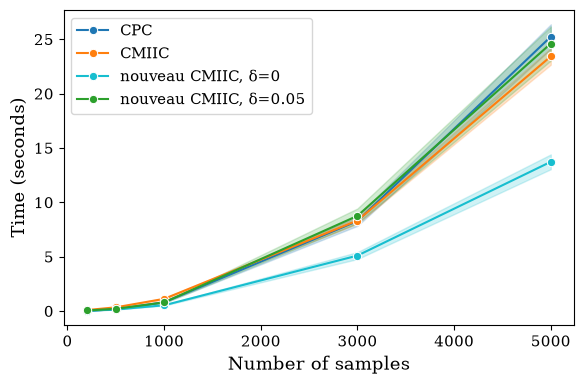

In [5]:
plot(df, 10, "time_s", "Time (seconds)")

### Sur les CPDAG

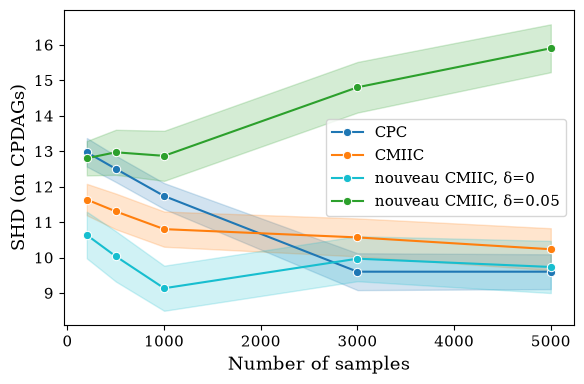

In [6]:
plot(df, 10, "SHD", "SHD (on CPDAGs)")

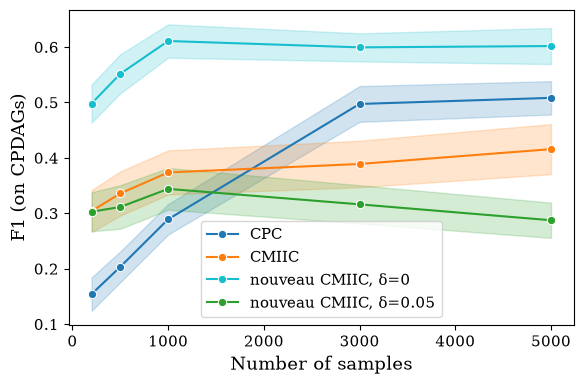

In [7]:
plot(df, 10, "F1-Score", "F1 (on CPDAGs)")

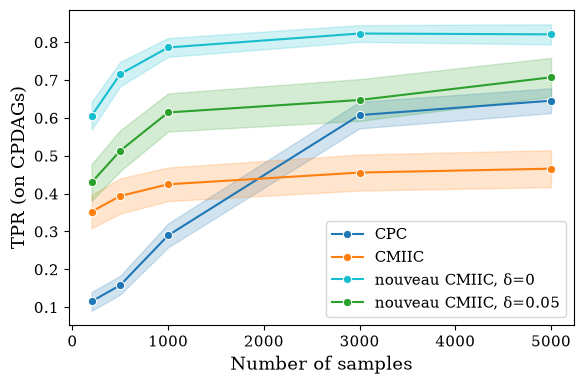

In [8]:
plot(df, 10, "TPR", "TPR (on CPDAGs)")

### Sur les squelettes

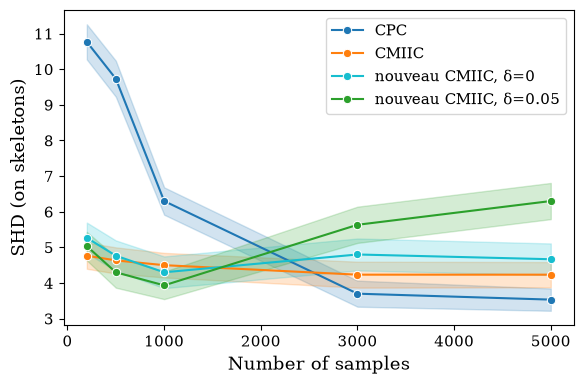

In [9]:
plot(df, 10, "SHD_skeleton", "SHD (on skeletons)")

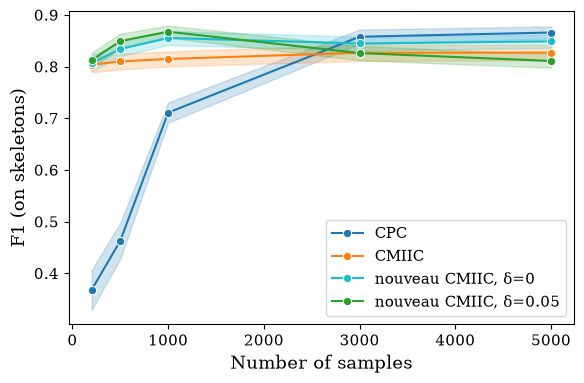

In [10]:
plot(df, 10, "F1-Score_skeleton", "F1 (on skeletons)")

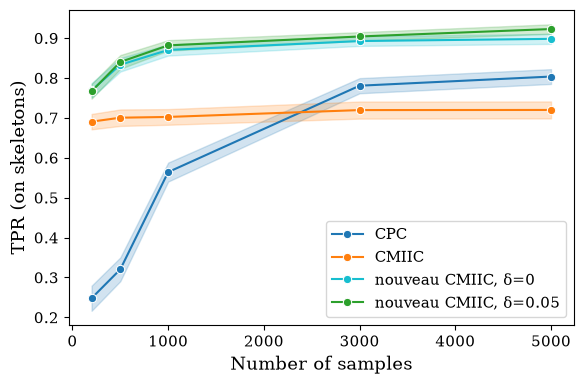

In [11]:
plot(df, 10, "TPR_skeleton", "TPR (on skeletons)")

## 20 variables

### Temps d'exécution

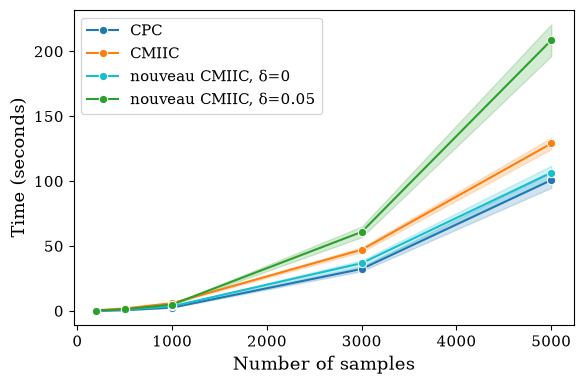

In [12]:
plot(df, 20, "time_s", "Time (seconds)")

### Sur les CPDAG

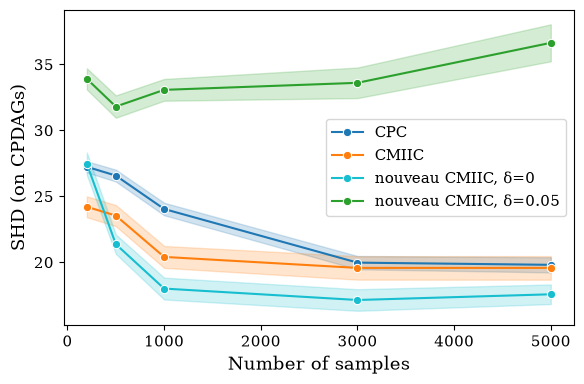

In [13]:
plot(df, 20, "SHD", "SHD (on CPDAGs)")

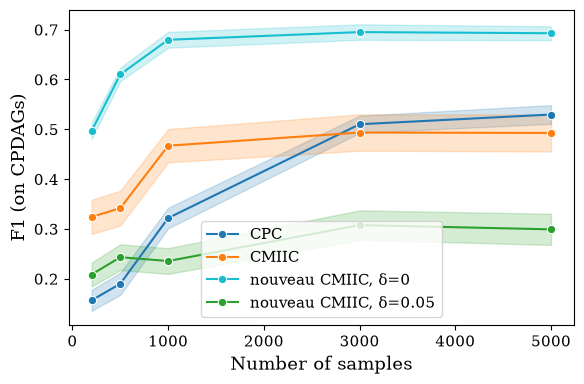

In [14]:
plot(df, 20, "F1-Score", "F1 (on CPDAGs)")

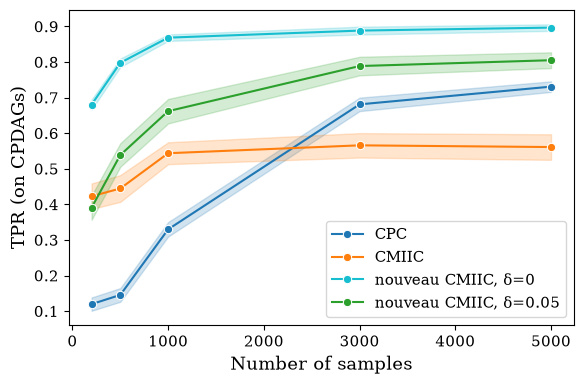

In [15]:
plot(df, 20, "TPR", "TPR (on CPDAGs)")

### Sur les squelettes

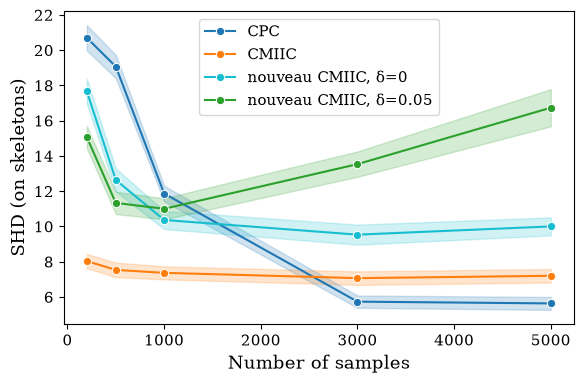

In [16]:
plot(df, 20, "SHD_skeleton", "SHD (on skeletons)")

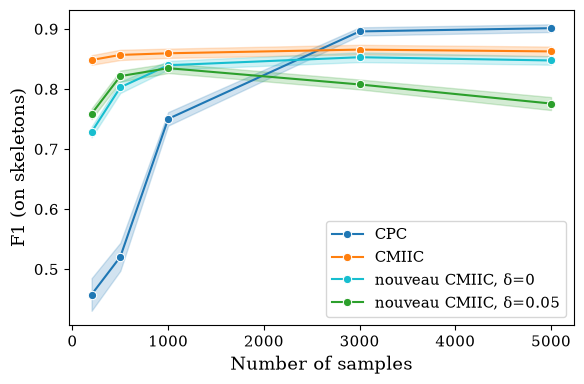

In [17]:
plot(df, 20, "F1-Score_skeleton", "F1 (on skeletons)")

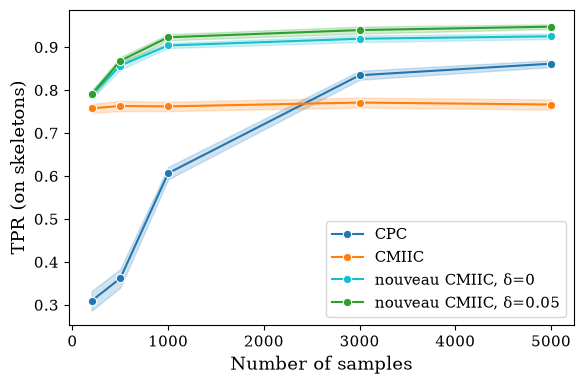

In [18]:
plot(df, 20, "TPR_skeleton", "TPR (on skeletons)")

# SEM Laplace

## Cohérence entre les deux runs du nouveau CMIIC

In [19]:
diff = check_skeleton("sem_laplace")
diff

sem_laplace : 300 cellules
  squelettes identiques : 53 / 300
  CPDAG identiques      : 2 / 300
  erreurs δ=0 : 0, erreurs δ=0.05 : 0


SHD_skeleton_d0  F1-Score_skeleton_d0  \
n_vars n_samples graph_idx                                          
10     200       1                      6.0              0.769231   
                 2                      4.0              0.846154   
                 4                      6.0              0.785714   
                 6                      5.0              0.838710   
                 8                      5.0              0.814815   
...                                     ...                   ...   
20     5000      25                    11.0              0.840580   
                 26                    11.0              0.835821   
                 27                     8.0              0.882353   
                 28                     5.0              0.923077   
                 29                     8.0              0.875000   

                            TPR_skeleton_d0  SHD_skeleton_d005  \
n_vars n_samples graph_idx                                       
10     200       1                 0.714286                5.0   
                 2                 0.733333                5.0   
                 4                 0.733333                5.0   
                 6                 0.866667                4.0   
                 8                 0.785714                4.0   
...                                     ...                ...   
20     5000      25                0.966667               18.0   
                 26                0.933333               16.0   
                 27                1.000000               20.0   
                 28                1.000000                8.0   
                 29                0.933333               28.0   

                            F1-Score_skeleton_d005  TPR_skeleton_d005  
n_vars n_samples graph_idx                                             
10     200       1                        0.800000           0.714286  
                 2                        0.800000           0.666667  
                 4                        0.814815           0.733333  
                 6                        0.866667           0.866667  
                 8                        0.846154           0.785714  
...                                            ...                ...  
20     5000      25                       0.763158           0.966667  
                 26                       0.783784           0.966667  
                 27                       0.750000           1.000000  
                 28                       0.882353           1.000000  
                 29                       0.674419           0.966667  

[247 rows x 6 columns]

## Erreurs du run δ=0.05

In [20]:
d005 = load_results(f"{D005['sem_laplace']}/results.csv")
d005.loc[d005.error_msg.notna(), KEYS + ["error_msg"]]

,n_vars,n_samples,graph_idx,error_msg


In [21]:
df = load_all("sem_laplace")

## 10 variables

### Temps d'exécution

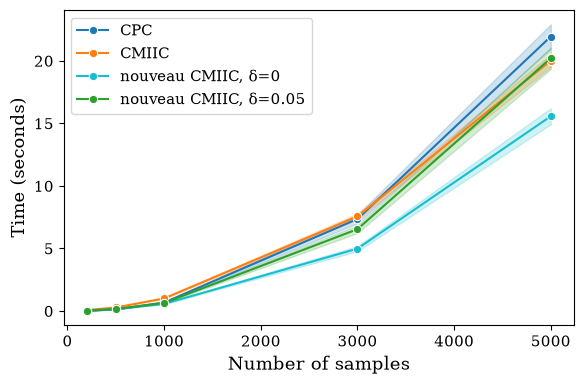

In [22]:
plot(df, 10, "time_s", "Time (seconds)")

### Sur les CPDAG

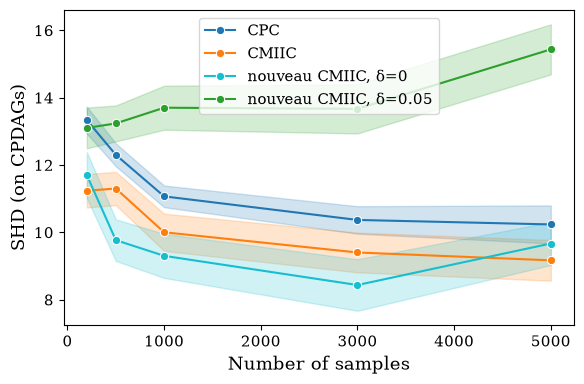

In [23]:
plot(df, 10, "SHD", "SHD (on CPDAGs)")

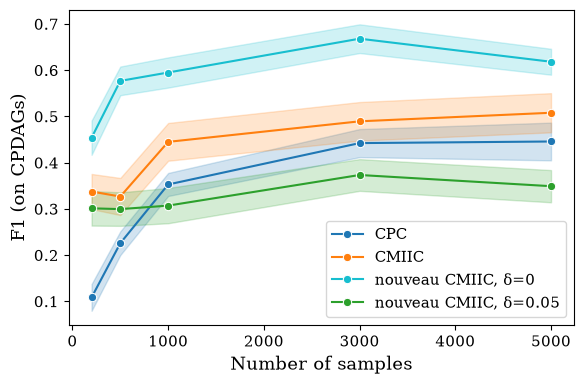

In [24]:
plot(df, 10, "F1-Score", "F1 (on CPDAGs)")

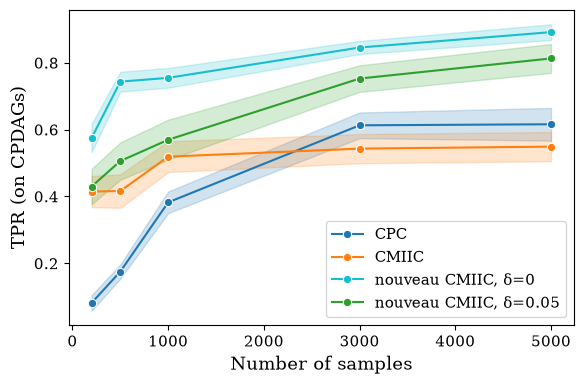

In [25]:
plot(df, 10, "TPR", "TPR (on CPDAGs)")

### Sur les squelettes

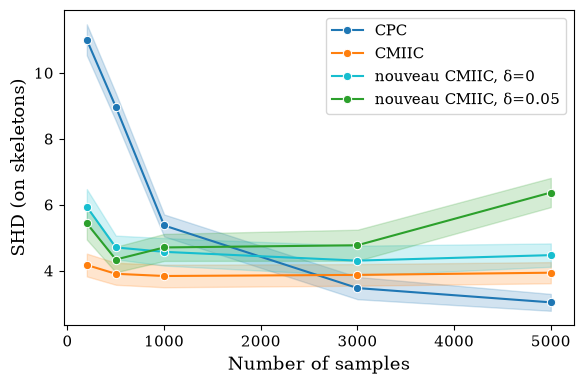

In [26]:
plot(df, 10, "SHD_skeleton", "SHD (on skeletons)")

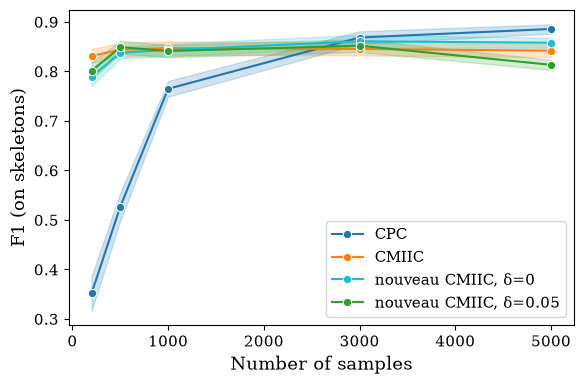

In [27]:
plot(df, 10, "F1-Score_skeleton", "F1 (on skeletons)")

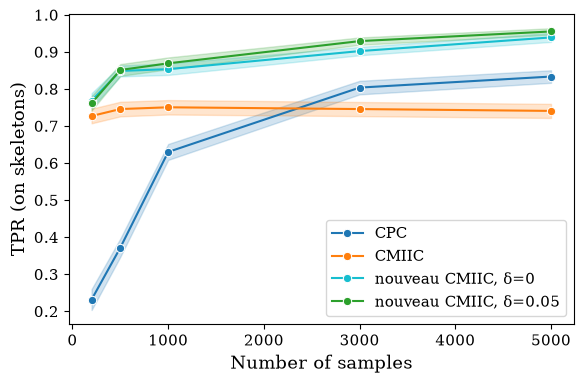

In [28]:
plot(df, 10, "TPR_skeleton", "TPR (on skeletons)")

## 20 variables

### Temps d'exécution

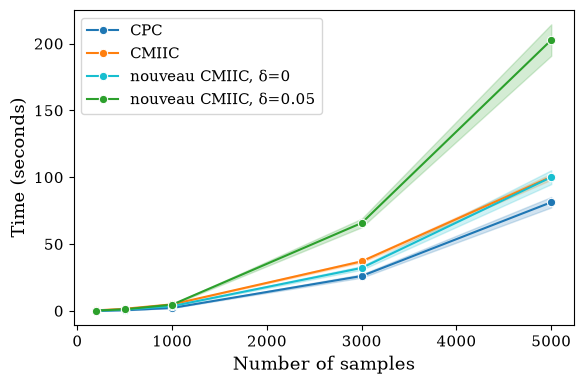

In [29]:
plot(df, 20, "time_s", "Time (seconds)")

### Sur les CPDAG

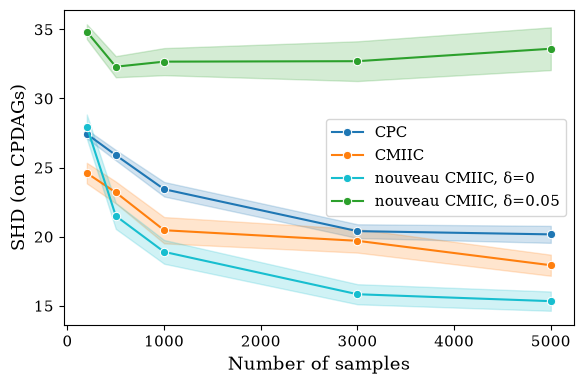

In [30]:
plot(df, 20, "SHD", "SHD (on CPDAGs)")

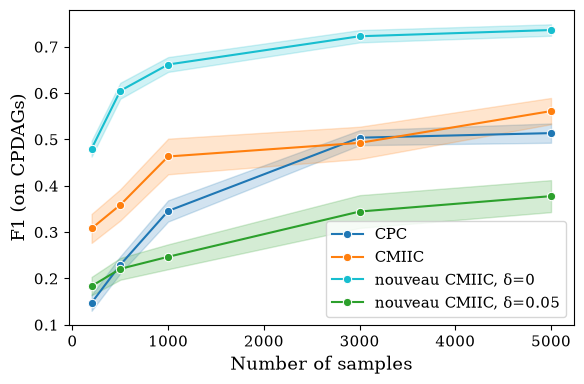

In [31]:
plot(df, 20, "F1-Score", "F1 (on CPDAGs)")

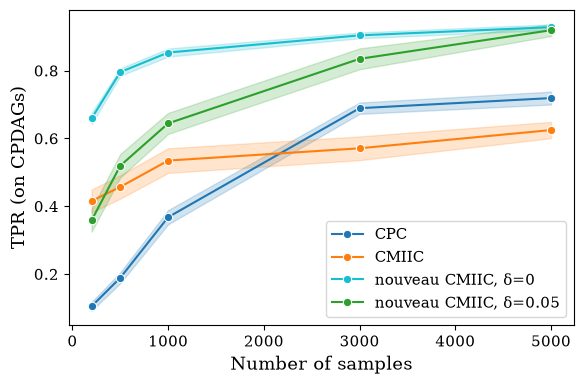

In [32]:
plot(df, 20, "TPR", "TPR (on CPDAGs)")

### Sur les squelettes

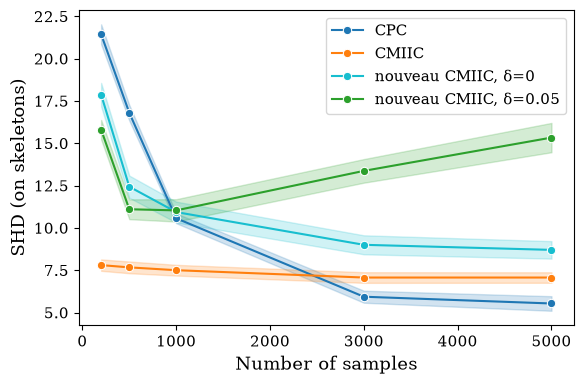

In [33]:
plot(df, 20, "SHD_skeleton", "SHD (on skeletons)")

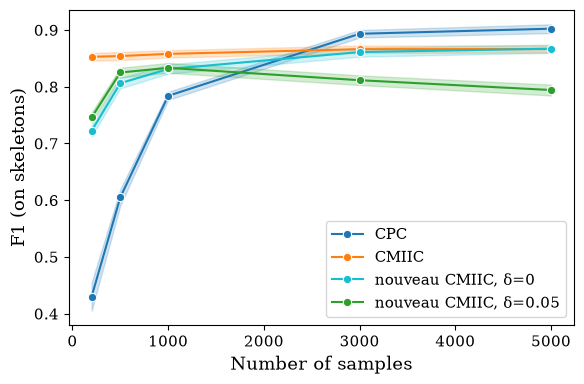

In [34]:
plot(df, 20, "F1-Score_skeleton", "F1 (on skeletons)")

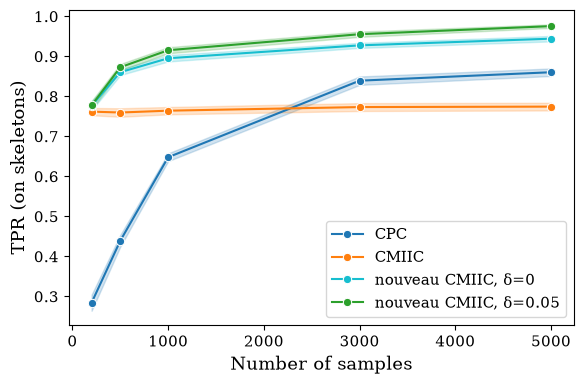

In [35]:
plot(df, 20, "TPR_skeleton", "TPR (on skeletons)")